# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [3]:
DATA_PATH = RAW_DATA_DIR / "wine.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [4]:
print("Forma:", df.shape)
print("\nTipos:\n", df.dtypes.value_counts())
print("\nNulos totales:", int(df.isna().sum().sum()))
print("Duplicados:", int(df.duplicated().sum()))
print("\nDistribución del target (conteo):\n", df["target"].value_counts().sort_index())
print("\nDistribución del target (proporción):\n", df["target"].value_counts(normalize=True).sort_index().round(3))
print("\nValores mínimos y máximos por variable:")
df.describe().T[["min", "mean", "max"]].round(2)

Forma: (178, 14)

Tipos:
 float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Duplicados: 0

Distribución del target (conteo):
 target
0    59
1    71
2    48
Name: count, dtype: int64

Distribución del target (proporción):
 target
0    0.331
1    0.399
2    0.270
Name: proportion, dtype: float64

Valores mínimos y máximos por variable:


,min,mean,max
alcohol,11.03,13.00,14.83
malic_acid,0.74,2.34,5.80
ash,1.36,2.37,3.23
alcalinity_of_ash,10.60,19.49,30.00
magnesium,70.00,99.74,162.00
total_phenols,0.98,2.30,3.88
flavanoids,0.34,2.03,5.08
nonflavanoid_phenols,0.13,0.36,0.66
proanthocyanins,0.41,1.59,3.58
color_intensity,1.28,5.06,13.00


**Conclusión de calidad:**

> El dataset tiene 178 filas, 13 variables numéricas continuas y el target con tres clases (0, 1 y 2). No hay valores nulos ni filas duplicadas, así que no hace falta imputar ni eliminar registros en esta etapa. Las clases están ligeramente desbalanceadas (59, 71 y 48 filas, es decir 33 %, 40 % y 27 %), no lo suficiente para requerir remuestreo, pero sí para justificar un split estratificado y usar F1 macro además de accuracy. Las escalas de las variables son muy distintas (por ejemplo `proline` llega a más de 1600 y `hue` ronda 1), lo que anticipa que los modelos sensibles a la escala (regresión logística, KNN) necesitarán estandarización dentro del pipeline. Decisión: conservar los datos tal cual y delegar el escalado al preprocesamiento del siguiente challenge.

## 2. Split train/test

In [5]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["target"],
    random_state=RANDOM_STATE,
)

In [6]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

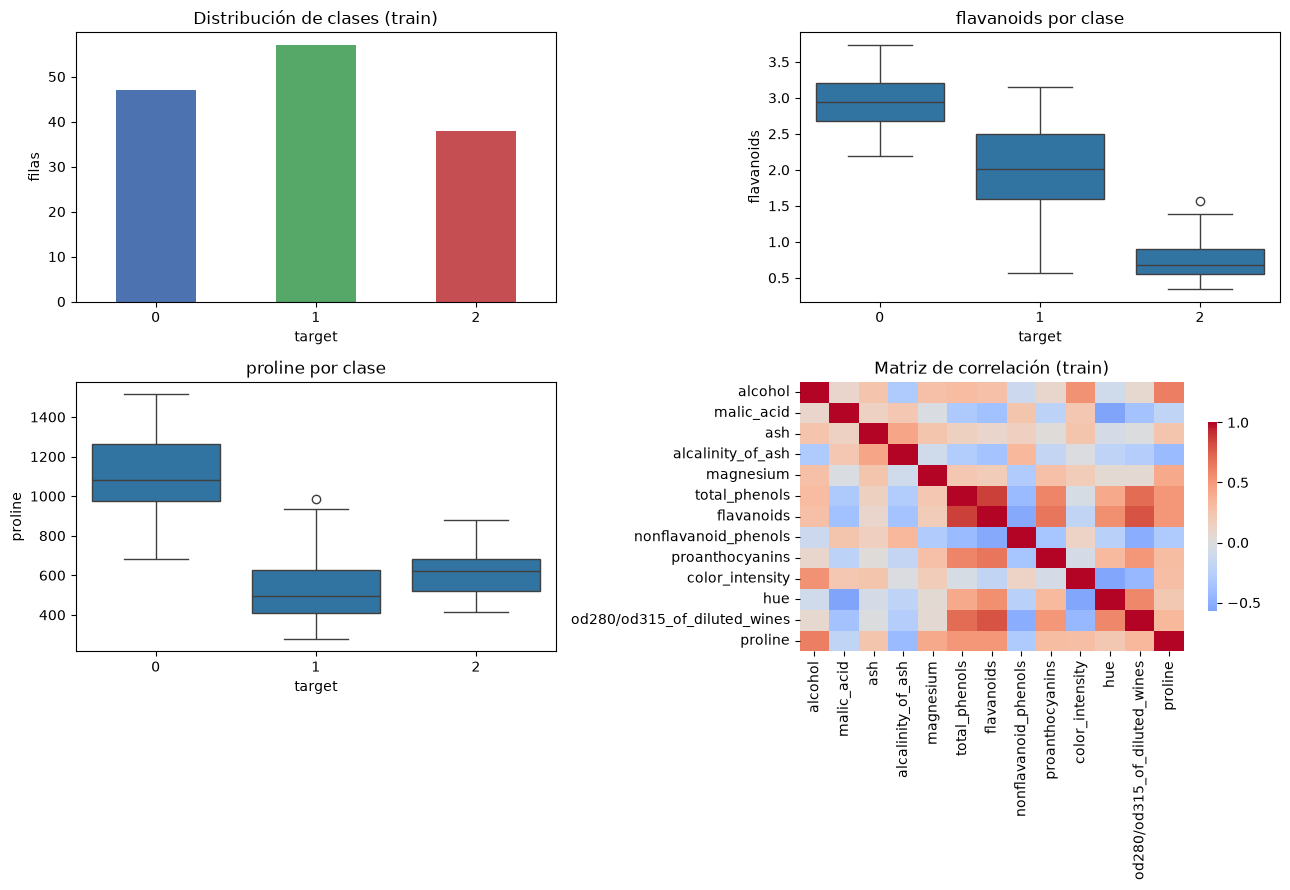

Correlación de cada variable con el target (train):
flavanoids                     -0.87
od280/od315_of_diluted_wines   -0.78
total_phenols                  -0.71
proline                        -0.64
hue                            -0.61
alcalinity_of_ash               0.51
Name: target, dtype: float64

Pares de variables más correlacionados:
total_phenols  flavanoids                      0.86
flavanoids     od280/od315_of_diluted_wines    0.79
total_phenols  od280/od315_of_diluted_wines    0.69
flavanoids     proanthocyanins                 0.66
dtype: float64

Rango (max/min) de medias por variable:
nonflavanoid_phenols      0.36
proline                 739.48
dtype: float64


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1) Distribución de clases
train_df["target"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 0], color=["#4C72B0", "#55A868", "#C44E52"])
axes[0, 0].set_title("Distribución de clases (train)")
axes[0, 0].set_xlabel("target")
axes[0, 0].set_ylabel("filas")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2) Boxplots de variables relevantes por clase
for ax, col in zip([axes[0, 1], axes[1, 0]], ["flavanoids", "proline"]):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax)
    ax.set_title(f"{col} por clase")

# 3) Correlaciones
corr = train_df.drop(columns="target").corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=axes[1, 1], cbar_kws={"shrink": 0.7})
axes[1, 1].set_title("Matriz de correlación (train)")
plt.tight_layout()
plt.show()

# Apoyo numérico para los hallazgos
print("Correlación de cada variable con el target (train):")
print(train_df.corr()["target"].drop("target").sort_values(key=abs, ascending=False).round(2).head(6))

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .sort_values(key=abs, ascending=False).head(4).round(2))
print("\nPares de variables más correlacionados:")
print(pairs)
print("\nRango (max/min) de medias por variable:")
print(train_df.drop(columns="target").mean().sort_values().round(2).iloc[[0, -1]])

**Hallazgos:**

1. Las clases están moderadamente desbalanceadas (en train, aproximadamente 33 %, 40 % y 27 %). No exige remuestreo, pero confirma que el split debe ser estratificado y que conviene reportar F1 macro junto a accuracy.
2. Varias variables separan muy bien las clases: `flavanoids` (correlación con el target de -0.87), `od280/od315_of_diluted_wines` (-0.78), `total_phenols` (-0.71) y `proline` (-0.64). Los boxplots muestran medianas casi sin solapamiento entre clases en `flavanoids` y `proline`, así que se espera un desempeño alto incluso con modelos simples.
3. Hay multicolinealidad entre variables relacionadas con fenoles (`total_phenols` y `flavanoids` con 0.86; `flavanoids` y `od280/od315` con 0.79) y las escalas son muy distintas (la media de `proline` ronda 740 frente a 0.36 de `nonflavanoid_phenols`). Esto exige estandarizar dentro del pipeline para KNN y regresión logística, y sugiere que la regularización será útil en la regresión logística. Los árboles no necesitan escalado.


## 4. Persistencia de datos y contrato

In [8]:
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "target": "target",
    "features": [c for c in df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
}
(ARTIFACTS_DIR / "data_contract.json").write_text(json.dumps(contract, indent=2), encoding="utf-8")
print(json.dumps(contract, indent=2))

{
  "target": "target",
  "features": [
    "alcohol",
    "malic_acid",
    "ash",
    "alcalinity_of_ash",
    "magnesium",
    "total_phenols",
    "flavanoids",
    "nonflavanoid_phenols",
    "proanthocyanins",
    "color_intensity",
    "hue",
    "od280/od315_of_diluted_wines",
    "proline"
  ],
  "random_state": 42,
  "test_size": 0.2
}


In [9]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [x] Cargué el CSV desde `data/raw`.
- [x] Revisé calidad y distribución de la clase.
- [x] Realicé un split estratificado.
- [x] No exploré el conjunto de test.
- [x] Guardé los tres artefactos requeridos.